# Consumo de alcohol

Sabéis que nos preocupa mucho la salud de los ciudadanos. Por eso nos han encargado hacer un análisis sobre el consumo de alcohol.

Los datos de referencia los encontraréis aquí: https://raw.githubusercontent.com/justmarkham/DAT8/master/data/drinks.csv

Nos interesa conocer el consumo de alcohol, por tipo de bebida alcohólica para los distintos continentes y países. Además, sabiendo que el vino y la cerveza son los sospechosos habituales, podéis disponer estadísticas sobre estos dos casos en particular.

In [2]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

In [3]:
dataframe=pd.read_csv("https://raw.githubusercontent.com/justmarkham/DAT8/master/data/drinks.csv", sep=",")

In [59]:
dataframe.tail(5)

,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
188,Venezuela,333,100,3,7.7,SA
189,Vietnam,111,2,1,2.0,AS
190,Yemen,6,0,0,0.1,AS
191,Zambia,32,19,4,2.5,AF
192,Zimbabwe,64,18,4,4.7,AF


In [4]:
dataframe["continent"].unique()
df=dataframe.fillna("NA")
df.info()
df.tail(25)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 193 entries, 0 to 192
Data columns (total 6 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   country                       193 non-null    object 
 1   beer_servings                 193 non-null    int64  
 2   spirit_servings               193 non-null    int64  
 3   wine_servings                 193 non-null    int64  
 4   total_litres_of_pure_alcohol  193 non-null    float64
 5   continent                     193 non-null    object 
dtypes: float64(1), int64(3), object(2)
memory usage: 9.2+ KB


,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
168,Tajikistan,2,15,0,0.3,AS
169,Thailand,99,258,1,6.4,AS
170,Macedonia,106,27,86,3.9,EU
171,Timor-Leste,1,1,4,0.1,AS
172,Togo,36,2,19,1.3,AF
173,Tonga,36,21,5,1.1,OC
174,Trinidad & Tobago,197,156,7,6.4,NA
175,Tunisia,51,3,20,1.3,AF
176,Turkey,51,22,7,1.4,AS
177,Turkmenistan,19,71,32,2.2,AS


In [6]:
dataframe["promedio_alcohol_por_serving"]=dataframe["total_litres_of_pure_alcohol"]/(dataframe["beer_servings"]+ dataframe["spirit_servings"]+dataframe ["wine_servings"])

In [7]:
dataframe.head()

,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent,promedio_alcohol_por_serving
0,Afghanistan,0,0,0,0.0,AS,NaN
1,Albania,89,132,54,4.9,EU,0.017818
2,Algeria,25,0,14,0.7,AF,0.017949
3,Andorra,245,138,312,12.4,EU,0.017842
4,Angola,217,57,45,5.9,AF,0.018495


In [8]:
dataframe["promedio_alcohol_por_serving"].fillna(0, inplace=True)

C:\Users\unaif\AppData\Local\Temp\ipykernel_17444\169230489.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  dataframe["promedio_alcohol_por_serving"].fillna(0, inplace=True)


C:\Users\unaif\AppData\Local\Temp\ipykernel_17444\791797589.py:2: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(x="total_litres_of_pure_alcohol", data= dataframe, hue="continent", shade=True)


<Axes: xlabel='total_litres_of_pure_alcohol', ylabel='Density'>

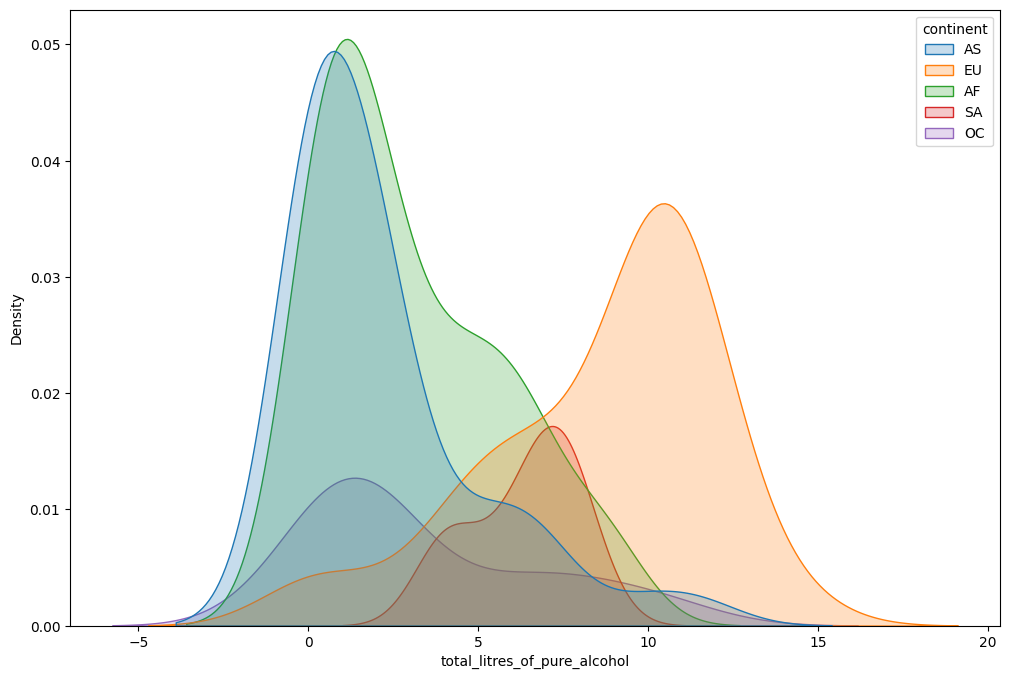

In [9]:
plt.figure(figsize=(12,8))
sns.kdeplot(x="total_litres_of_pure_alcohol", data= dataframe, hue="continent", shade=True)

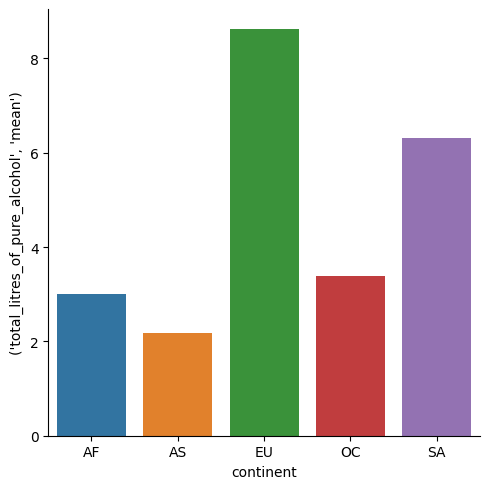

In [15]:
df_agg=dataframe.groupby("continent").aggregate({"total_litres_of_pure_alcohol": ["mean", "std"]} )
sns.catplot(y=("total_litres_of_pure_alcohol", "mean"), x="continent", data=df_agg, hue="continent", kind="bar")

In [16]:
eu_data=dataframe[dataframe["continent"]=="EU"]
eu_data["common_alcohol"]=eu_data["beer_servings"]+eu_data["wine_servings"]
eu_data=eu_data.sort_values(by="common_alcohol", ascending=False)
eu_data.head()

C:\Users\unaif\AppData\Local\Temp\ipykernel_17444\2796158293.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  eu_data["common_alcohol"]=eu_data["beer_servings"]+eu_data["wine_servings"]


,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent,promedio_alcohol_por_serving,common_alcohol
3,Andorra,245,138,312,12.4,EU,0.017842,557
156,Slovenia,270,51,276,10.6,EU,0.017755,546
136,Portugal,194,67,339,11.0,EU,0.018333,533
65,Germany,346,117,175,11.3,EU,0.017712,521
16,Belgium,295,84,212,10.5,EU,0.017766,507


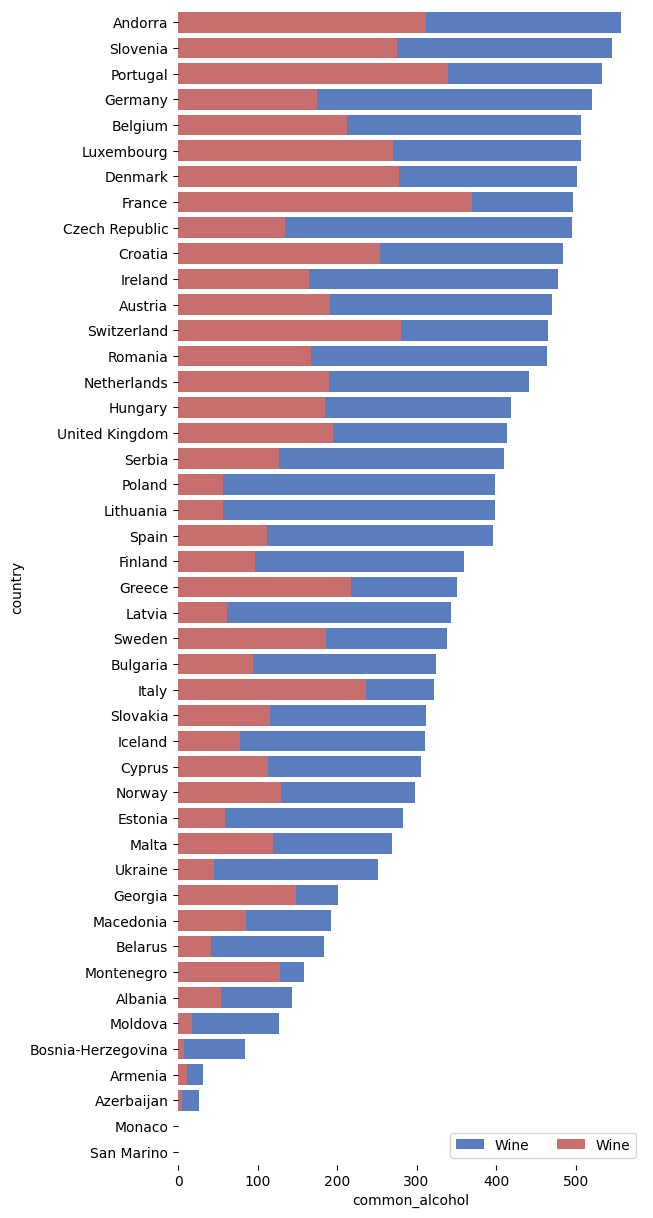

In [20]:
f, ax=plt.subplots(figsize=(6,15))

sns.set_color_codes("muted")
sns.barplot(x="common_alcohol", y= "country", data=eu_data, label="Wine", color="b")

sns.set_color_codes("muted")
sns.barplot(x="wine_servings", y= "country", data=eu_data, label="Wine", color="r")

ax.legend(ncol=3, loc="lower right", frameon=True)
sns.despine(left=True, bottom=True)